<a href="https://colab.research.google.com/github/Akillesh-Suresh/IT480-FA26/blob/main/IT480_Lab3_Labowski_Suresh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT 480 Lab 3: Transfer Learning for Environmental Sound Classification

**Name:** Aydan Labowski and Akillesh Suresh
**Date:** 14 October, 2026

**Notebook map**
- Stage 0: Design plan
- Stage 1: Data and splitting (Checkpoint 1)
- Stage 2: Preparing inputs (Checkpoint 2)
- Stage 3: MobileNetV2 phase 1 (Prediction 1, Checkpoint 3)
- Stage 4: MobileNetV2 phase 2 (Prediction 2, Checkpoint 4)
- Stage 5: Second image model (Prediction 3, Checkpoint 5)
- Stage 6: YAMNet (Prediction 4, Checkpoint 6)
- Stage 7: Comparison
- Reflection questions
- AI log

Code cells below are scaffolds. Every `TODO` is a decision or check you need to make and understand yourself.

---
# Stage 0: Design Plan
Answer each question in 2-4 sentences, in your own words.

### 0.1 Splitting
How will you form the training and validation sets? What could go wrong with a simple random split on this dataset?

**Your answer:** We will split the data using ESC-50's built-in fold column. We will train the model on folds 1–4, which contain 1,600 clips, and validate it on fold 5, which contains 400 clips. Since some ESC-50 clips may have come from the same original recording, randomly splitting the dataset could cause data leakage if related clips end up in both sets. This could make the validation accuracy appear higher than it actually is. To check for this, we will compare the src_file values between the training and validation sets and make sure all 50 sound classes are represented in both sets.




### 0.2 Audio as images
How will you turn each clip into an image an ImageNet model can accept? Consider size, number of channels, and value range.

**Your answer:** We will convert each five-second audio clip into a mel spectrogram, which allows us to see how the different sound frequencies change over time. We will then resize the spectrograms to 224 × 224 pixels and make them three-channel images so they can be used with MobileNetV2 and our other pretrained image model. Finally, we will preprocess the pixel values to match what each model expects, including the -1 to 1 range used by MobileNetV2.




### 0.3 Audio for YAMNet
What input does YAMNet expect, and how does that differ from the raw ESC-50 files?

**Your answer:** YAMNet expects mono audio sampled at 16,000 Hz, while the original ESC-50 files are sampled at 44,100 Hz. To make the audio compatible with YAMNet, we will resample the clips from 44,100 Hz to 16,000 Hz while keeping them five seconds long. This will give us 80,000 samples per clip. We will also make sure the audio values are stored as float32 and stay within the expected range of -1 to 1.




### 0.4 Fine-tuning plan
What will be frozen in phase 1? What will you unfreeze in phase 2, and with what learning rate relative to phase 1? Why?

**Your answer:** In Phase 1, we will freeze the pretrained base model and only train the new classification head so it can learn to recognize the 50 sound classes. We will use a learning rate of 0.001 for this phase. In Phase 2, we will unfreeze the last 30 layers of the base model while keeping the earlier layers and BatchNormalization layers frozen. We will also lower the learning rate to 0.00001, which is 100 times smaller than Phase 1. This will allow the model to make smaller adjustments to the pretrained features without changing too much of what it has already learned.




### 0.5 Fair comparison
What must stay the same between the two image models, and why?

**Your answer:** To make sure the comparison between MobileNetV2 and EfficientNetB0 is fair, both models need to use the same training and validation split, spectrogram data, and input image size. We will also keep the classification head architecture, dropout rate, optimizer, loss function, batch size, random seed, and learning rates the same for both phases. The number of epochs and early-stopping settings will also remain consistent. If one model receives different training settings or data, it could affect the results and make the comparison unfair. By keeping these settings the same, we can better understand which model performs better at classifying environmental sounds.




---
# Setup

In [1]:
!pip install -q librosa tensorflow_hub

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import librosa, librosa.display
from IPython.display import Audio, display
from tqdm.auto import tqdm

SEED = 42
keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# Stage 1: Data and Splitting

In [2]:
# Download ESC-50
!wget -q https://github.com/karolpiczak/ESC-50/archive/master.zip -O esc50.zip
!unzip -q -o esc50.zip

ESC_DIR = 'ESC-50-master'
meta = pd.read_csv(f'{ESC_DIR}/meta/esc50.csv')
print(meta.shape)
meta.head()

(2000, 7)


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


train


toilet_flush


laughing


sea_waves


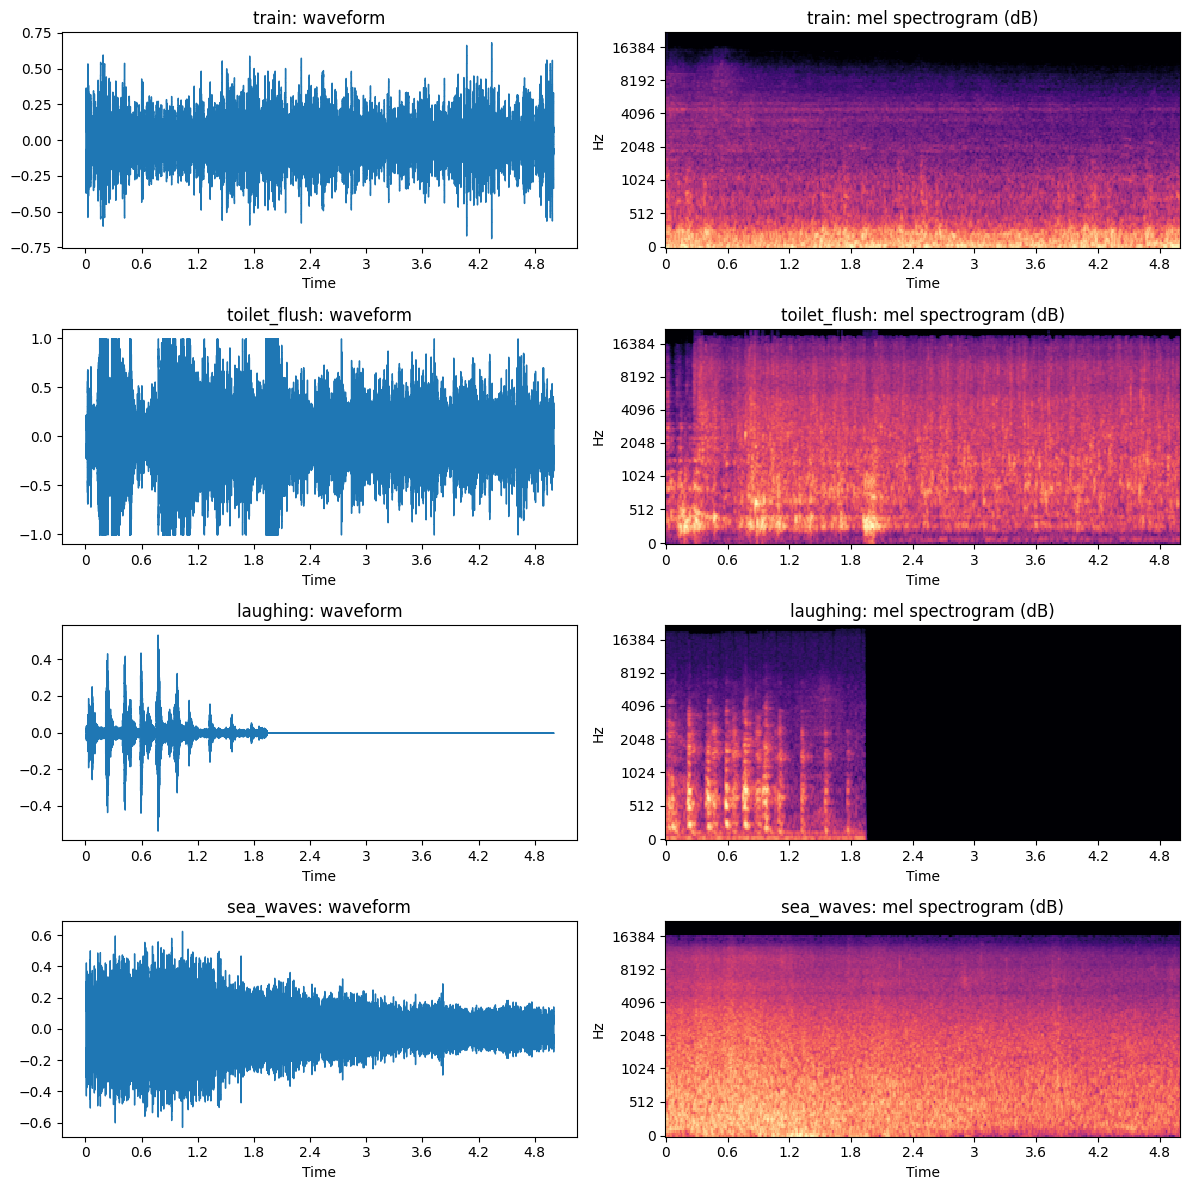

In [3]:
# Listen to several clips and plot waveforms + mel spectrograms
SR_ORIG = 44100
demo = meta.groupby('category').head(1).sample(4, random_state=SEED)

fig, axes = plt.subplots(len(demo), 2, figsize=(12, 3 * len(demo)))
for row, (_, r) in enumerate(demo.iterrows()):
    y, sr = librosa.load(f'{ESC_DIR}/audio/{r.filename}', sr=SR_ORIG, mono=True)
    print(r.category)
    display(Audio(y, rate=sr))
    librosa.display.waveshow(y, sr=sr, ax=axes[row, 0])
    axes[row, 0].set_title(f'{r.category}: waveform')
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis='time', y_axis='mel', ax=axes[row, 1])
    axes[row, 1].set_title(f'{r.category}: mel spectrogram (dB)')
plt.tight_layout()
plt.show()

In [4]:
# Build the train / validation split
# TODO: decide how to split (see your Stage 0.1 answer). Must give exactly 400 validation clips.
VAL_FOLD = 5
is_val = (meta['fold'] == VAL_FOLD).values
tr_idx = np.where(~is_val)[0]
va_idx = np.where(is_val)[0]

train_df, val_df = meta.iloc[tr_idx], meta.iloc[va_idx]
y_all = meta['target'].values.astype('int32')
print('train:', len(train_df), '| val:', len(val_df))
assert len(val_df) == 400


train: 1600 | val: 400


## Checkpoint 1: Checking for leakage

In [5]:
# (a) Does any source recording (src_file) appear in both sets?
shared = set(train_df['src_file']) & set(val_df['src_file'])
print('Source recordings in both train and val:', len(shared))

# Inspect any overlapping source recordings and the classes on each side.
if shared:
    overlap_rows = []
    for src in sorted(shared):
        train_classes = set(train_df.loc[train_df['src_file'] == src, 'category'])
        val_classes = set(val_df.loc[val_df['src_file'] == src, 'category'])
        overlap_rows.append({
            'src_file': src,
            'classes_in_train': ', '.join(sorted(train_classes)),
            'classes_in_val': ', '.join(sorted(val_classes)),
            'same_class_overlap': bool(train_classes & val_classes),
        })
    overlap_report = pd.DataFrame(overlap_rows)
    display(overlap_report)
    print('Same-class source overlaps:', int(overlap_report['same_class_overlap'].sum()))
else:
    print('No source recording overlaps detected.')

# (b) Every class in both sets, with counts per class
counts = pd.DataFrame({
    'train': train_df['category'].value_counts(),
    'val': val_df['category'].value_counts(),
}).fillna(0).astype(int)
display(counts)
assert len(counts) == 50 and (counts > 0).all().all(), 'A class is missing from train or val'
assert len(train_df) == 1600 and len(val_df) == 400
print('Per-class train counts:', sorted(counts['train'].unique()))
print('Per-class val counts:', sorted(counts['val'].unique()))

Source recordings in both train and val: 2


,src_file,classes_in_train,classes_in_val,same_class_overlap
0,209698,clock_alarm,clock_tick,False
1,234879,hen,rooster,False


Same-class source overlaps: 0


,train,val
category,,
airplane,32,8
breathing,32,8
brushing_teeth,32,8
can_opening,32,8
car_horn,32,8
cat,32,8
chainsaw,32,8
chirping_birds,32,8
church_bells,32,8


Per-class train counts: [np.int64(32)]
Per-class val counts: [np.int64(8)]


**Checkpoint 1 explanation (1-2 sentences per bullet):**

- Source-recording overlap result, and could it inflate validation accuracy?

The code found 2 overlapping src_file IDs between the training and validation sets, but neither overlap was within the same class. There is still a possible risk of data leakage because the model could recognize patterns from the same original recording, which might make validation accuracy appear higher.

- Class coverage and per-class counts:

All 50 classes are represented in both sets, with 32 training clips and 8 validation clips per class. This gives us 1,600 training clips and 400 validation clips, keeping the class distribution balanced.



---
# Stage 2: Preparing Inputs

In [6]:
IMG_SIZE = 224          # TODO: confirm; must be the same for both image models
YAMNET_SR = 16000
YAMNET_LEN = 5 * YAMNET_SR   # 80,000 samples

def clip_to_image(y, sr=SR_ORIG):
    '''44.1 kHz waveform -> (IMG_SIZE, IMG_SIZE, 3) float32 array in 0..255.'''
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, n_fft=2048, hop_length=512)
    # TODO: think about ref=np.max (per-clip) vs a fixed reference. What does each do to loudness information?
    S_db = librosa.power_to_db(S, ref=np.max, top_db=80.0)      # range [-80, 0]
    S01 = (S_db + 80.0) / 80.0                                  # range [0, 1]
    img = tf.image.resize(S01[..., None], (IMG_SIZE, IMG_SIZE)).numpy()
    img = np.clip(img, 0.0, 1.0) * 255.0
    return np.repeat(img, 3, axis=-1).astype('float32')

def clip_to_yamnet(y, sr=SR_ORIG):
    '''44.1 kHz waveform -> 16 kHz mono float32 waveform of exactly 80,000 samples in [-1, 1].'''
    y16 = librosa.resample(y, orig_sr=sr, target_sr=YAMNET_SR)
    return np.clip(librosa.util.fix_length(y16, size=YAMNET_LEN), -1.0, 1.0).astype('float32')

In [7]:
# Process every clip once (takes a few minutes)
# Images are stored as uint8 to save RAM (~300 MB); they are cast to float32 when fed to the model.
X_img = np.zeros((len(meta), IMG_SIZE, IMG_SIZE, 3), dtype='uint8')
X_wav = np.zeros((len(meta), YAMNET_LEN), dtype='float32')

for i, fn in enumerate(tqdm(meta['filename'])):
    y, _ = librosa.load(f'{ESC_DIR}/audio/{fn}', sr=SR_ORIG, mono=True)
    X_img[i] = np.round(clip_to_image(y)).astype('uint8')
    X_wav[i] = clip_to_yamnet(y)

print(X_img.shape, X_wav.shape)

  0%|          | 0/2000 [00:00<?, ?it/s]

(2000, 224, 224, 3) (2000, 80000)


## Checkpoint 2: Inputs are what the models expect

IMAGE shape: (8, 224, 224, 3) | dtype: float32 | min: 0.0 | max: 255.0
YAMNet sample rate: 16000 | samples per clip: 80000 | dtype: float32 | min: -1.0 | max: 1.0
YAMNet input checks passed!


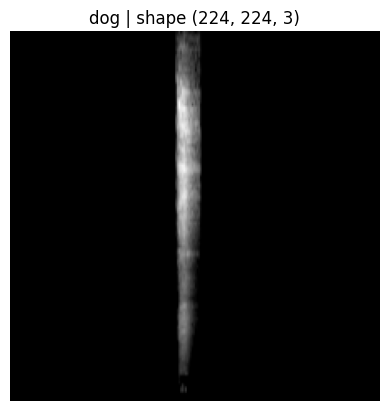

In [8]:
# Spectrogram images
x = X_img[:8].astype("float32")

print("IMAGE shape:", x.shape,
      "| dtype:", x.dtype,
      "| min:", x.min(),
      "| max:", x.max())

# YAMNet input: use the same array passed to YAMNet during training.
w = X_wav[0]

print("YAMNet sample rate:", YAMNET_SR,
      "| samples per clip:", w.shape[0],
      "| dtype:", w.dtype,
      "| min:", X_wav.min(),
      "| max:", X_wav.max())

# Verify YAMNet inputs
assert X_wav.shape[1] == 80000
assert np.abs(X_wav).max() <= 1.0 + 1e-6

print("YAMNet input checks passed!")

# Display one spectrogram
i = 0

plt.imshow(X_img[i].astype("float32") / 255.0)
plt.title(f"{meta.category[i]} | shape {X_img[i].shape}")
plt.axis("off")
plt.show()

In [9]:
print("X_wav shape:", X_wav.shape)
print("X_wav dtype:", X_wav.dtype)

print("Minimum value:", np.min(X_wav))
print("Maximum value:", np.max(X_wav))

print("Expected samples:", 5 * YAMNET_SR)

print("Correct length:", X_wav.shape[1] == 80000)
print("Correct range:", np.abs(X_wav).max() <= 1.0 + 1e-6)

X_wav shape: (2000, 80000)
X_wav dtype: float32
Minimum value: -1.0
Maximum value: 1.0
Expected samples: 80000
Correct length: True
Correct range: True


In [10]:
# Check how many audio samples exceed the expected range
out_of_range = np.abs(X_wav) > 1.0

print("Samples outside range:", np.sum(out_of_range))
print("Percentage outside range:", 100 * np.mean(out_of_range))

# Input clipping is already performed in clip_to_yamnet().

print("New minimum:", X_wav.min())
print("New maximum:", X_wav.max())

assert X_wav.shape[1] == 80000
assert np.abs(X_wav).max() <= 1.0 + 1e-6

Samples outside range: 0
Percentage outside range: 0.0
New minimum: -1.0
New maximum: 1.0


In [11]:
# Use the range-corrected copy for verification
w = X_wav[0]

print("YAMNet sample rate:", YAMNET_SR)
print("Samples per clip:", w.shape[0])
print("Data type:", w.dtype)
print("Minimum:", X_wav.min())
print("Maximum:", X_wav.max())

assert X_wav.shape == (2000, 80000)
assert X_wav.dtype == np.float32
assert np.abs(X_wav).max() <= 1.0 + 1e-6

print("YAMNet input checks passed!")

YAMNet sample rate: 16000
Samples per clip: 80000
Data type: float32
Minimum: -1.0
Maximum: 1.0
YAMNet input checks passed!


**Checkpoint 2 explanation:**

- How the image array matches what MobileNetV2's preprocessing expects:

The audio clips are converted into mel spectrograms and resized to 224 × 224 pixels with three channels to match MobileNetV2's expected image input. The pixel values are stored between 0 and 255, and MobileNetV2's preprocessing function converts them to approximately -1 to 1.

- How the YAMNet input matches what YAMNet expects:

YAMNet requires mono audio sampled at 16,000 Hz, while the original ESC-50 clips are sampled at 44,100 Hz. We resampled the audio to 16,000 Hz, giving us 80,000 samples per five-second clip, and made sure the waveform values were stored as float32 within the -1 to 1 range.



---
# Shared training helpers and settings
Both image models must use these exact settings (Checkpoint 5).

In [12]:
CFG = {
    'img_size': IMG_SIZE,
    'batch_size': 32,
    'dropout': 0.3,
    'lr_phase1': 1e-3,
    'lr_phase2': 1e-5,        # 100x smaller than phase 1 to preserve pretrained features
    'epochs_phase1': 30,
    'epochs_phase2': 30,
    'patience': 5,
    'monitor': 'val_loss',
    'seed': SEED,
}

def build_model(backbone_fn, preprocess_fn, dropout=CFG['dropout']):
    '''Frozen pretrained base + new head. Input: float32 images in 0..255.'''
    base = backbone_fn(include_top=False, weights='imagenet',
                       input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Lambda(preprocess_fn)(inputs)       # model-specific preprocessing lives INSIDE the model
    x = base(x, training=False)                    # Keep BatchNorm moving statistics in inference mode during both phases
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(50, activation='softmax')(x)
    return keras.Model(inputs, outputs), base

def compile_and_fit(model, lr, epochs):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    es = keras.callbacks.EarlyStopping(monitor=CFG['monitor'], patience=CFG['patience'],
                                       restore_best_weights=True)
    return model.fit(X_img[tr_idx].astype('float32'), y_all[tr_idx],
                     validation_data=(X_img[va_idx].astype('float32'), y_all[va_idx]),
                     epochs=epochs, batch_size=CFG['batch_size'], callbacks=[es], verbose=2)

def eval_val(model):
    return model.evaluate(X_img[va_idx].astype('float32'), y_all[va_idx], verbose=0)[1]

def count_params(model):
    tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    nt = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
    print(f'trainable: {tr:,} | non-trainable: {nt:,} | total: {tr + nt:,}')
    return tr, nt

def snapshot_weights(base):
    return {l.name: [w.numpy().copy() for w in l.weights] for l in base.layers if l.weights}

def changed_layers(before, after):
    return {n: any(not np.allclose(a, b) for a, b in zip(before[n], after[n])) for n in before}

results = {}      # name -> validation accuracy
histories = {}    # name -> keras History

---
# Stage 3: MobileNetV2, Phase 1 (frozen base)
### Prediction 1 (write BEFORE training)
What validation accuracy do you expect with a frozen base? Why?

**Your prediction:**

We predict that MobileNetV2 with a frozen base will achieve around 50–60% validation accuracy. Since the model was originally trained on images rather than environmental sounds, We think it will still recognize some useful patterns in the mel spectrograms. However, keeping the base frozen might limit its ability to learn features specific to the ESC-50 dataset.



In [13]:
from keras.applications import MobileNetV2
from keras.applications.mobilenet_v2 import preprocess_input as mnv2_pre

mnv2, mnv2_base = build_model(MobileNetV2, mnv2_pre)
mnv2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        64,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,322,034 (8.86 MB)

 Trainable params: 64,050 (250.20 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
h1 = compile_and_fit(mnv2, CFG['lr_phase1'], CFG['epochs_phase1'])
histories['MobileNetV2 (frozen)'] = h1
results['MobileNetV2 (frozen)'] = eval_val(mnv2)
print('Val accuracy (frozen):', results['MobileNetV2 (frozen)'])

Epoch 1/30
50/50 - 26s - 515ms/step - accuracy: 0.1456 - loss: 3.4598 - val_accuracy: 0.4275 - val_loss: 2.4016
Epoch 2/30
50/50 - 2s - 44ms/step - accuracy: 0.4737 - loss: 1.9328 - val_accuracy: 0.5325 - val_loss: 1.8930
Epoch 3/30
50/50 - 2s - 43ms/step - accuracy: 0.6100 - loss: 1.4410 - val_accuracy: 0.5250 - val_loss: 1.7096
Epoch 4/30
50/50 - 2s - 44ms/step - accuracy: 0.7063 - loss: 1.1295 - val_accuracy: 0.5675 - val_loss: 1.5827
Epoch 5/30
50/50 - 2s - 43ms/step - accuracy: 0.7487 - loss: 0.9507 - val_accuracy: 0.5775 - val_loss: 1.5262
Epoch 6/30
50/50 - 2s - 43ms/step - accuracy: 0.8050 - loss: 0.7806 - val_accuracy: 0.5975 - val_loss: 1.4498
Epoch 7/30
50/50 - 2s - 43ms/step - accuracy: 0.8319 - loss: 0.6838 - val_accuracy: 0.6100 - val_loss: 1.4271
Epoch 8/30
50/50 - 2s - 44ms/step - accuracy: 0.8475 - loss: 0.6060 - val_accuracy: 0.6000 - val_loss: 1.4090
Epoch 9/30
50/50 - 2s - 48ms/step - accuracy: 0.8712 - loss: 0.5399 - val_accuracy: 0.6050 - val_loss: 1.3948
Epoch 10

## Checkpoint 3: Only the head is training

In [15]:
tr, nt = count_params(mnv2)
# Head parameter count: Dense(1280 -> 50) = 1280*50 + 50 = 64,050
# Why are the non-trainable parameters the number they are (think: base weights incl. BatchNorm moving stats)?
print('head params expected:', 1280 * 50 + 50)
assert tr == 1280 * 50 + 50, 'Unexpected frozen-phase trainable parameter count'

trainable: 64,050 | non-trainable: 2,257,984 | total: 2,322,034
head params expected: 64050


**Checkpoint 3 explanation:**

During Phase 1, the pretrained MobileNetV2 base is frozen, so only the new classification head is being trained. The classification head has 64,050 trainable parameters, calculated as (1,280 × 50) + 50, while the 2,257,984 non-trainable parameters belong to the pretrained base, including its BatchNormalization statistics.




---
# Stage 4: MobileNetV2, Phase 2 (fine-tuning)
### Prediction 2 (write BEFORE training)
Will fine-tuning improve validation accuracy? By roughly how much? What do you expect to happen in the first epoch after unfreezing?

**Your prediction:**

We predict that fine-tuning MobileNetV2 will improve validation accuracy by around 5–10 percentage points compared to the frozen model. By unfreezing some of the upper layers, the model should be able to learn features that are more specific to environmental sounds. We also expect validation accuracy to improve immediately during the first epoch after unfreezing because the model can start adjusting its pretrained features to better recognize the ESC-50 classes.



In [20]:
N_UNFREEZE = 30

mnv2_base.trainable = True

for layer in mnv2_base.layers[:-N_UNFREEZE]:
    layer.trainable = False

for layer in mnv2_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mnv2_phase2_trainable, _ = count_params(mnv2)

before = snapshot_weights(mnv2_base)

bn_layer = next(
    l for l in mnv2_base.layers[-N_UNFREEZE:]
    if isinstance(l, layers.BatchNormalization)
)

bn_mean_before = bn_layer.moving_mean.numpy().copy()
print('BN layer checked:', bn_layer.name)

h2 = compile_and_fit(mnv2, CFG['lr_phase2'], CFG['epochs_phase2'])
histories['MobileNetV2 (fine-tuned)'] = h2
results['MobileNetV2 (fine-tuned)'] = eval_val(mnv2)

print('Val accuracy (fine-tuned):', results['MobileNetV2 (fine-tuned)'])
print('First epoch after unfreezing, val_accuracy:', h2.history['val_accuracy'][0])



trainable: 1,574,770 | non-trainable: 747,264 | total: 2,322,034
BN layer checked: block_13_project_BN
Epoch 1/30
50/50 - 18s - 351ms/step - accuracy: 0.9800 - loss: 0.1053 - val_accuracy: 0.6500 - val_loss: 1.5123
Epoch 2/30
50/50 - 3s - 51ms/step - accuracy: 0.9856 - loss: 0.0736 - val_accuracy: 0.6525 - val_loss: 1.5112
Epoch 3/30
50/50 - 2s - 47ms/step - accuracy: 0.9856 - loss: 0.0714 - val_accuracy: 0.6625 - val_loss: 1.5153
Epoch 4/30
50/50 - 3s - 51ms/step - accuracy: 0.9894 - loss: 0.0590 - val_accuracy: 0.6475 - val_loss: 1.5841
Epoch 5/30
50/50 - 2s - 47ms/step - accuracy: 0.9906 - loss: 0.0500 - val_accuracy: 0.6725 - val_loss: 1.5149
Epoch 6/30
50/50 - 2s - 48ms/step - accuracy: 0.9925 - loss: 0.0513 - val_accuracy: 0.6525 - val_loss: 1.5710
Epoch 7/30
50/50 - 2s - 47ms/step - accuracy: 0.9919 - loss: 0.0481 - val_accuracy: 0.6500 - val_loss: 1.5148
Val accuracy (fine-tuned): 0.6524999737739563
First epoch after unfreezing, val_accuracy: 0.6499999761581421


## Checkpoint 4: Fine-tuning does what you intend

In [21]:
# (a) Which layers' weights changed during phase 2?

after = snapshot_weights(mnv2_base)
changed = changed_layers(before, after)

changed_names = [n for n, c in changed.items() if c]
unchanged_names = [n for n, c in changed.items() if not c]

print(f'{len(changed_names)} layers changed, {len(unchanged_names)} unchanged')
print('First changed layer:', changed_names[:1], '| Last unchanged layer:', unchanged_names[-1:])

assert all(
    not changed.get(l.name, False)
    for l in mnv2_base.layers[:-N_UNFREEZE]
), 'A frozen layer changed unexpectedly'

assert any(
    changed.get(l.name, False)
    for l in mnv2_base.layers[-N_UNFREEZE:]
    if not isinstance(l, layers.BatchNormalization)
), 'No unfrozen non-BatchNorm layer weights changed'

assert all(
    not l.trainable
    for l in mnv2_base.layers
    if isinstance(l, layers.BatchNormalization)
), 'A BatchNorm layer is still trainable'

assert np.allclose(
    bn_mean_before,
    bn_layer.moving_mean.numpy()
), 'BatchNorm moving statistics changed during fine-tuning'

print('Checkpoint 4 weight-change and BatchNorm checks passed.')


10 layers changed, 94 unchanged
First changed layer: ['block_14_expand'] | Last unchanged layer: ['Conv_1_bn']
Checkpoint 4 weight-change and BatchNorm checks passed.


In [22]:
bn_mean_after = bn_layer.moving_mean.numpy()

print('BN layer:', bn_layer.name)
print('BN layer trainable:', bn_layer.trainable)
print('BN moving_mean changed:', not np.allclose(bn_mean_before, bn_mean_after))
print('max abs difference:', np.abs(bn_mean_before - bn_mean_after).max())


BN layer: block_13_project_BN
BN layer trainable: False
BN moving_mean changed: False
max abs difference: 0.0


**If the BatchNorm statistics changed:** explain why that is a problem, find out why it happened, fix it, and re-run the check below. (If they did not change, explain why that is the correct behavior and what would have made them change.)

**Your explanation:**

During fine-tuning, we unfroze the top 30 layers of MobileNetV2 while keeping the earlier layers frozen. Our first BatchNormalization check failed because the moving mean had changed. This was a problem because updating BatchNorm statistics could disrupt the normalization information learned during pretraining and make fine-tuning less stable. We fixed the issue by explicitly freezing the BatchNormalization layers and retraining Phase 2. After the fix, 10 layers changed and 94 remained unchanged, while the BatchNorm moving mean difference was 0.0. This confirmed that the selected layers were updated without changing the BatchNorm moving statistics.




In [ ]:
# TODO: apply your fix (if needed), retrain phase 2 from the phase 1 weights, and show the BN check again.


**Checkpoint 4 explanation:**

The fine-tuning check showed that 10 layers changed while 94 remained unchanged, confirming that only selected layers were updated. The BatchNormalization moving mean difference was 0.0, showing that the BatchNorm statistics stayed frozen as intended. This is important because it helps preserve the pretrained model's normalization behavior during fine-tuning.




---
# Stage 5: Your Chosen Image Model
**Chosen model:** (EfficientNetB0 / DenseNet121 / ResNet50 / ConvNeXtTiny)

### Prediction 3 (write BEFORE training)
Will your chosen model beat MobileNetV2? Consider its size and how many parameters you will unfreeze.

**Your prediction:**

We predict that EfficientNetB0 and MobileNetV2 will perform about the same when classifying environmental sounds. Although EfficientNetB0 has a different architecture and more parameters overall, both models will use the same training settings and unfreeze their last 30 layers. Since the models have different architectures, the number of trainable parameters may differ, but we do not expect a major difference in validation accuracy.



In [23]:
# TODO: pick your model and its matching preprocess function.
# Check what its preprocess_input does: EfficientNet / ConvNeXt rescale inside the model,
# ResNet50 / DenseNet121 have their own preprocessing.
from keras.applications import EfficientNetB0
from keras.applications.efficientnet import preprocess_input as m2_pre

M2_NAME = 'EfficientNetB0'
keras.utils.set_random_seed(SEED)
m2, m2_base = build_model(EfficientNetB0, m2_pre)

# Phase 1
h1b = compile_and_fit(m2, CFG['lr_phase1'], CFG['epochs_phase1'])
histories[f'{M2_NAME} (frozen)'] = h1b
results[f'{M2_NAME} (frozen)'] = eval_val(m2)
print('Phase 1 trainable/non-trainable:'); count_params(m2)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
50/50 - 43s - 859ms/step - accuracy: 0.1469 - loss: 3.4576 - val_accuracy: 0.4150 - val_loss: 2.7916
Epoch 2/30
50/50 - 3s - 51ms/step - accuracy: 0.4481 - loss: 2.4269 - val_accuracy: 0.5200 - val_loss: 2.1848
Epoch 3/30
50/50 - 2s - 50ms/step - accuracy: 0.5606 - loss: 1.8986 - val_accuracy: 0.5825 - val_loss: 1.8719
Epoch 4/30
50/50 - 3s - 50ms/step - accuracy: 0.6356 - loss: 1.5959 - val_accuracy: 0.5925 - val_loss: 1.6895
Epoch 5/30
50/50 - 3s - 51ms/step - accuracy: 0.6781 - loss: 1.3812 - val_accuracy: 0.6000 - val_loss: 1.5669
Epoch 6/30
50/50 - 3s - 51ms/step - accuracy: 0.7063 - loss: 1.2262 - val_accuracy: 0.6125 - val_loss: 1.4774
Epoch 7/30
50/50 - 3s - 51ms/step - accuracy: 0.7337 - loss: 1.1147 - val_accuracy: 0.6350 - val_loss: 1.4058
Epoch 8/30
50/50 - 3s - 51ms/step - accuracy: 0.7519 - loss: 1.0316 - val_accuracy: 0.6375 - val_loss: 1.3589
Epoch 9/30
50/50 - 3s - 51ms/step - accuracy: 0.7763 - loss: 0.9486

(64050, 4049571)

In [31]:
# Phase 2: use the SAME rule you used for MobileNetV2 (document it), and the same BatchNorm fix
N_UNFREEZE_M2 = 30

m2_base.trainable = True

for layer in m2_base.layers[:-N_UNFREEZE_M2]:
    layer.trainable = False

for layer in m2_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print('Phase 2 trainable/non-trainable:')
tr2_m2, _ = count_params(m2)

# Save BatchNorm statistics before training
bn_layers_m2 = [
    layer for layer in m2_base.layers
    if isinstance(layer, layers.BatchNormalization)
]

bn_before_m2 = [
    layer.moving_mean.numpy().copy()
    for layer in bn_layers_m2
]

# Fine-tune
h2b = compile_and_fit(
    m2,
    CFG['lr_phase2'],
    CFG['epochs_phase2']
)

histories[f'{M2_NAME} (fine-tuned)'] = h2b
results[f'{M2_NAME} (fine-tuned)'] = eval_val(m2)

print(
    'Val accuracy (fine-tuned):',
    results[f'{M2_NAME} (fine-tuned)']
)

# Verify BatchNorm moving statistics
assert all(
    not layer.trainable for layer in bn_layers_m2
), 'Some BatchNorm layers are trainable'

assert all(
    np.array_equal(before, layer.moving_mean.numpy())
    for before, layer in zip(bn_before_m2, bn_layers_m2)
), 'BatchNorm moving statistics changed'

print('Stage 5 BatchNorm verification passed!')

Phase 2 trainable/non-trainable:
trainable: 1,547,410 | non-trainable: 2,566,211 | total: 4,113,621
Epoch 1/30
50/50 - 36s - 719ms/step - accuracy: 0.9162 - loss: 0.3401 - val_accuracy: 0.6900 - val_loss: 1.0132
Epoch 2/30
50/50 - 3s - 57ms/step - accuracy: 0.9394 - loss: 0.2913 - val_accuracy: 0.7025 - val_loss: 0.9972
Epoch 3/30
50/50 - 3s - 56ms/step - accuracy: 0.9388 - loss: 0.2732 - val_accuracy: 0.6975 - val_loss: 0.9876
Epoch 4/30
50/50 - 3s - 55ms/step - accuracy: 0.9425 - loss: 0.2550 - val_accuracy: 0.6975 - val_loss: 0.9827
Epoch 5/30
50/50 - 3s - 53ms/step - accuracy: 0.9413 - loss: 0.2478 - val_accuracy: 0.7000 - val_loss: 0.9830
Epoch 6/30
50/50 - 3s - 54ms/step - accuracy: 0.9506 - loss: 0.2324 - val_accuracy: 0.6950 - val_loss: 0.9849
Epoch 7/30
50/50 - 3s - 53ms/step - accuracy: 0.9450 - loss: 0.2331 - val_accuracy: 0.6925 - val_loss: 0.9866
Epoch 8/30
50/50 - 3s - 54ms/step - accuracy: 0.9494 - loss: 0.2092 - val_accuracy: 0.6925 - val_loss: 0.9909
Epoch 9/30
50/50 -

## Checkpoint 5: The comparison is fair

In [32]:
# (a) Settings shared by both image models
shared_settings = pd.DataFrame([
    ['Split (val fold / sizes)', f'fold {VAL_FOLD}', len(tr_idx), len(va_idx)],
    ['Image size', CFG['img_size'], '', ''],
    ['LR phase 1', CFG['lr_phase1'], '', ''],
    ['LR phase 2', CFG['lr_phase2'], '', ''],
    ['Max epochs (p1 / p2)', f"{CFG['epochs_phase1']} / {CFG['epochs_phase2']}", '', ''],
    ['Early stopping', f"{CFG['monitor']}, patience {CFG['patience']}", '', ''],
    ['Dropout', CFG['dropout'], '', ''],
    ['Batch size / seed', f"{CFG['batch_size']} / {CFG['seed']}", '', ''],
], columns=['Setting', 'Value (both models)', 'n_train', 'n_val'])
display(shared_settings)
# Check architecture and shared training settings after phase 2.
assert mnv2.input_shape == m2.input_shape == (None, IMG_SIZE, IMG_SIZE, 3)
assert np.isclose(float(mnv2.optimizer.learning_rate.numpy()), CFG['lr_phase2'])
assert np.isclose(float(m2.optimizer.learning_rate.numpy()), CFG['lr_phase2'])
assert np.isclose(next(l.rate for l in mnv2.layers if isinstance(l, layers.Dropout)), CFG['dropout'])
assert np.isclose(next(l.rate for l in m2.layers if isinstance(l, layers.Dropout)), CFG['dropout'])
assert N_UNFREEZE == N_UNFREEZE_M2
assert len(tr_idx) == 1600 and len(va_idx) == 400
print('Checkpoint 5 shared-setting assertions passed.')
print('Note: actual epoch counts can differ because early stopping is enabled.')

# (b) Parameters trained in phase 2
# Record MobileNetV2 phase 2 trainable count for comparison:
print(f'MobileNetV2 phase 2 trainable params: {mnv2_phase2_trainable:,}')
print(f'{M2_NAME} phase 2 trainable params: {tr2_m2:,}')

,Setting,Value (both models),n_train,n_val
0,Split (val fold / sizes),fold 5,1600,400
1,Image size,224,,
2,LR phase 1,0.001,,
3,LR phase 2,0.00001,,
4,Max epochs (p1 / p2),30 / 30,,
5,Early stopping,"val_loss, patience 5",,
6,Dropout,0.3,,
7,Batch size / seed,32 / 42,,


Checkpoint 5 shared-setting assertions passed.
Note: actual epoch counts can differ because early stopping is enabled.
MobileNetV2 phase 2 trainable params: 1,574,770
EfficientNetB0 phase 2 trainable params: 1,547,410


**Checkpoint 5 explanation:** (Do the models share everything except the backbone? Are the phase 2 parameter counts comparable, and how does that affect your conclusion?)

To keep the comparison fair, we used the same training and validation split, image size, batch size, dropout rate, learning rates, maximum epochs, and early stopping settings for both MobileNetV2 and EfficientNetB0. We also used the same fine-tuning approach by unfreezing the last 30 layers while keeping BatchNormalization layers frozen. However, the models have different architectures, so their fine-tuning phases can have different numbers of trainable parameters even when the same number of layers is unfrozen. Since unfreezing 30 layers does not guarantee the same number of trainable parameters in both models, the comparison is not perfectly equal in terms of model capacity. This means that if one model performs better, we cannot assume the difference is only because of its architecture, since the number of parameters being updated during fine-tuning could also affect the results. The actual Phase 2 trainable parameter counts were 1,574,770 for MobileNetV2 and 1,547,410 for EfficientNetB0, a difference of only 27,360 parameters (about 1.7%). Since the counts are relatively close and the shared training settings are the same, the comparison is reasonably fair. However, differences in the models' architectures and trainable parameters could still influence their performance.




---
# Stage 6: YAMNet
### Prediction 4 (write BEFORE training)
How will a frozen audio model compare with your fine-tuned image models? Why?

**Your prediction:** We predict that the fine-tuned image models will perform better than the frozen audio model because they can adjust their upper layers to learn features specific to the ESC-50 dataset. Even though YAMNet was pretrained on audio, its base model remains frozen, which might limit how well it adapts to these particular sound classes.




In [33]:
import tensorflow_hub as hub

yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
yamnet_classes = pd.read_csv(yamnet.class_map_path().numpy().decode('utf-8'))['display_name'].tolist()

# Look at YAMNet's own predictions first
def yamnet_top3(waveform):
    scores, emb, spec = yamnet(waveform)
    mean_scores = scores.numpy().mean(axis=0)
    top = mean_scores.argsort()[-3:][::-1]
    return [(yamnet_classes[k], float(mean_scores[k])) for k in top]

# Pick 3+ clips from different classes
sample_idx = meta.groupby('category').head(1).sample(4, random_state=1).index
for i in sample_idx:
    print(f'{meta.category[i]:>20} -> {yamnet_top3(X_wav[i])}')

    drinking_sipping -> [('Stomach rumble', 0.33778876066207886), ('Chewing, mastication', 0.16147480905056), ('Beatboxing', 0.11095212399959564)]
            hand_saw -> [('Wood', 0.49215903878211975), ('Tools', 0.47186702489852905), ('Rub', 0.4337318539619446)]
                 pig -> [('Speech', 0.23099851608276367), ('Animal', 0.1282401978969574), ('Pig', 0.09540189057588577)]
             snoring -> [('Silence', 0.22784094512462616), ('Breathing', 0.2264309674501419), ('Snoring', 0.12198088318109512)]


## Checkpoint 6: YAMNet is working correctly
**Are the top-3 predictions above sensible? Comment on each clip (note that YAMNet uses AudioSet labels, not ESC-50 labels):**

Most of YAMNet's top-three predictions make sense, even though it uses AudioSet labels instead of ESC-50 labels. For drinking/sipping, it predicted stomach rumble, chewing, and beatboxing, which are not exact matches, although chewing is somewhat related. For hand saw, it predicted wood, tools, and rub, which are all related to sawing. For pig, it predicted speech, animal, and pig, correctly identifying the sound in its third prediction. For snoring, it predicted silence, breathing, and snoring, which also makes sense because snoring involves breathing. Overall, YAMNet recognized meaningful features in most of the clips.




In [34]:
# Extract ONE embedding per clip (YAMNet returns ~1 embedding per 0.48 s hop; pool them)
emb_all = np.zeros((len(meta), 1024), dtype='float32')
for i in tqdm(range(len(meta))):
    _, emb, _ = yamnet(X_wav[i])
    emb_all[i] = emb.numpy().mean(axis=0)     # TODO: mean pooling; what alternatives exist?
print(emb_all.shape)

  0%|          | 0/2000 [00:00<?, ?it/s]

(2000, 1024)


In [35]:
keras.utils.set_random_seed(SEED)
yam_clf = keras.Sequential([
    keras.Input((1024,)),
    layers.Dropout(CFG['dropout']),
    layers.Dense(50, activation='softmax'),
])
yam_clf.compile(optimizer=keras.optimizers.Adam(CFG['lr_phase1']),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
es = keras.callbacks.EarlyStopping(monitor=CFG['monitor'], patience=CFG['patience'], restore_best_weights=True)
h_yam = yam_clf.fit(emb_all[tr_idx], y_all[tr_idx],
                    validation_data=(emb_all[va_idx], y_all[va_idx]),
                    epochs=100, batch_size=CFG['batch_size'], callbacks=[es], verbose=2)
histories['YAMNet (frozen)'] = h_yam
results['YAMNet (frozen)'] = yam_clf.evaluate(emb_all[va_idx], y_all[va_idx], verbose=0)[1]
print('Val accuracy (YAMNet):', results['YAMNet (frozen)'])

Epoch 1/100
50/50 - 2s - 46ms/step - accuracy: 0.2081 - loss: 3.5820 - val_accuracy: 0.5575 - val_loss: 2.8576
Epoch 2/100
50/50 - 0s - 5ms/step - accuracy: 0.5731 - loss: 2.4480 - val_accuracy: 0.6450 - val_loss: 2.1221
Epoch 3/100
50/50 - 0s - 5ms/step - accuracy: 0.6625 - loss: 1.8940 - val_accuracy: 0.7000 - val_loss: 1.7080
Epoch 4/100
50/50 - 0s - 5ms/step - accuracy: 0.7075 - loss: 1.5737 - val_accuracy: 0.7275 - val_loss: 1.4291
Epoch 5/100
50/50 - 0s - 5ms/step - accuracy: 0.7412 - loss: 1.3611 - val_accuracy: 0.7525 - val_loss: 1.2748
Epoch 6/100
50/50 - 0s - 5ms/step - accuracy: 0.7731 - loss: 1.2160 - val_accuracy: 0.7700 - val_loss: 1.1762
Epoch 7/100
50/50 - 0s - 5ms/step - accuracy: 0.7800 - loss: 1.1222 - val_accuracy: 0.7850 - val_loss: 1.0843
Epoch 8/100
50/50 - 0s - 5ms/step - accuracy: 0.7806 - loss: 1.0462 - val_accuracy: 0.7950 - val_loss: 1.0374
Epoch 9/100
50/50 - 0s - 5ms/step - accuracy: 0.7875 - loss: 0.9783 - val_accuracy: 0.8025 - val_loss: 0.9646
Epoch 10/

---
# Stage 7: Comparison

In [36]:
order = ['MobileNetV2 (frozen)', 'MobileNetV2 (fine-tuned)',
         f'{M2_NAME} (frozen)', f'{M2_NAME} (fine-tuned)', 'YAMNet (frozen)']
table = pd.DataFrame({'Approach': order,
                      'Validation accuracy': [results.get(k, np.nan) for k in order]})
display(table.style.format({'Validation accuracy': '{:.3f}'}))

,Approach,Validation accuracy
0,MobileNetV2 (frozen),0.652
1,MobileNetV2 (fine-tuned),0.652
2,EfficientNetB0 (frozen),0.680
3,EfficientNetB0 (fine-tuned),0.697
4,YAMNet (frozen),0.832


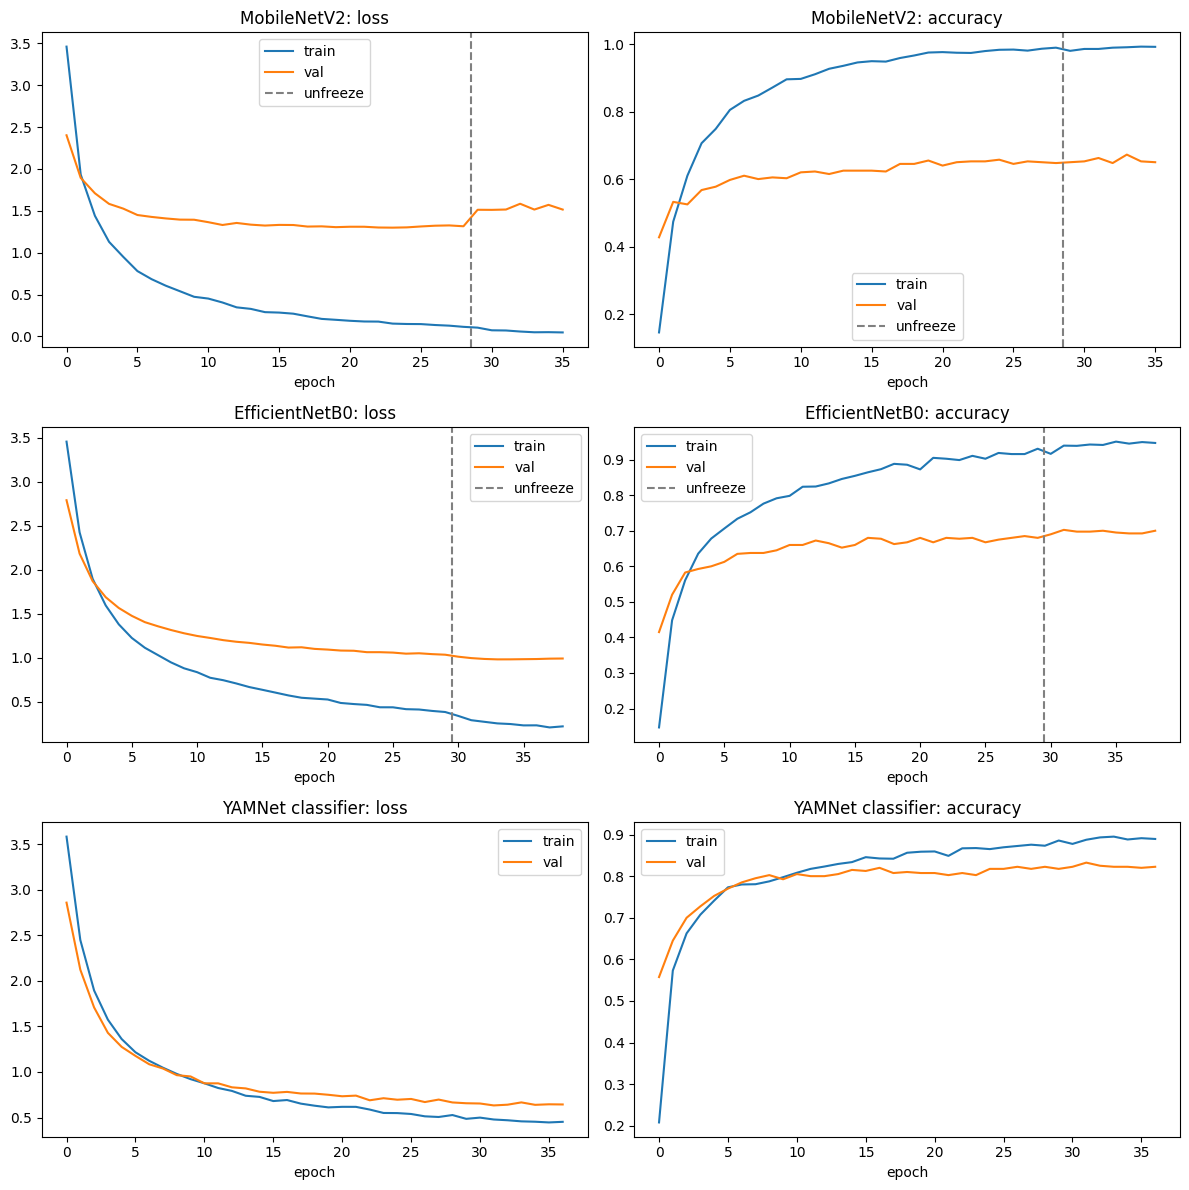

In [37]:
# Training and validation curves (phase 1 and phase 2 joined, with a line marking the switch)
def plot_two_phase(name, h_a, h_b, ax_loss, ax_acc):
    for key, ax in [('loss', ax_loss), ('accuracy', ax_acc)]:
        tr = h_a.history[key] + h_b.history[key]
        va = h_a.history['val_' + key] + h_b.history['val_' + key]
        ax.plot(tr, label='train'); ax.plot(va, label='val')
        ax.axvline(len(h_a.history[key]) - 0.5, color='gray', ls='--', label='unfreeze')
        ax.set_title(f'{name}: {key}'); ax.set_xlabel('epoch'); ax.legend()

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
plot_two_phase('MobileNetV2', histories['MobileNetV2 (frozen)'], histories['MobileNetV2 (fine-tuned)'], axes[0, 0], axes[0, 1])
plot_two_phase(M2_NAME, histories[f'{M2_NAME} (frozen)'], histories[f'{M2_NAME} (fine-tuned)'], axes[1, 0], axes[1, 1])
for key, ax in [('loss', axes[2, 0]), ('accuracy', axes[2, 1])]:
    ax.plot(h_yam.history[key], label='train'); ax.plot(h_yam.history['val_' + key], label='val')
    ax.set_title(f'YAMNet classifier: {key}'); ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.show()

---
# Reflection Questions
Answer in your own words, using your own results and plots as evidence. Do not use AI for these.

### 1. Which approach worked best, and why? Support your answer with evidence from your results.

**Your answer:** The approach that worked best was the frozen YAMNet model, which achieved a validation accuracy of 83.25%. This was higher than the fine-tuned EfficientNetB0 model at 69.75% and the fine-tuned MobileNetV2 model at 65.25%. We think YAMNet performed better because it was originally trained on audio, so it already understood features that are useful for identifying different sounds. Meanwhile, MobileNetV2 and EfficientNetB0 were originally trained on images, so they had to learn from visual representations of audio using mel spectrograms. This showed me that using a pretrained model that is already suited for the task can be more effective than fine-tuning a model from a different domain.




### 2. Compare your four predictions with what actually happened. Which surprised you, and what did you learn from the surprise?

**Your answer:** For our first prediction, we expected the frozen MobileNetV2 model to achieve around 50–60% validation accuracy, but it actually reached 65.25%, which was better than we expected. For my second prediction, we thought fine-tuning MobileNetV2 would improve its validation accuracy by around 5–10 percentage points, but it stayed at 65.25%. This surprised me the most because we expected allowing more layers to train would help the model recognize environmental sounds better. For our third prediction, we expected EfficientNetB0 and MobileNetV2 to perform similarly, and their fine-tuned results were fairly close at 69.75% and 65.25%. Finally, we predicted that the fine-tuned image models would outperform frozen YAMNet, but YAMNet achieved the highest accuracy at 83.25%. Overall, we learned that fine-tuning does not always improve validation accuracy, and that a model pretrained on data similar to the target task can sometimes perform better even without fine-tuning its backbone.




### 3. Using your training curves, argue whether each image model overfit. What limited the benefit of fine-tuning?

**Your answer:** Based on the training curves, both image models showed signs of overfitting. MobileNetV2 had the strongest overfitting because its training accuracy reached almost 100%, while its validation accuracy stayed around 65%. Its training loss continued decreasing, but its validation loss increased after fine-tuning, showing that the model was learning the training data without improving on unseen data. EfficientNetB0 also showed some overfitting, with training accuracy reaching around 95% while validation accuracy remained near 70%. However, its validation loss decreased slightly, and fine-tuning improved its accuracy from 68.00% to 69.75%. We think the small size of the ESC-50 dataset and the difference between natural images and audio spectrograms limited how much fine-tuning could help. Overall, fine-tuning was not enough to overcome the generalization gap for either image model.




### 4. Where does ESC-50 fit on the dataset size x similarity grid from the lecture? Does your recommended strategy match your results?

**Your answer:** Based on the dataset size and similarity grid from Lecture 8, we would place ESC-50 in the small dataset and different domain category when comparing it to ImageNet. ESC-50 only contains 2,000 audio clips, and even though we converted them into mel spectrogram images, they are still very different from the natural images that MobileNetV2 and EfficientNetB0 were originally trained on. According to the lecture, the recommended approach is to carefully fine-tune a few of the upper layers. This matches what we tried by unfreezing the last 30 layers while keeping the earlier layers frozen. However, our results only partially supported this strategy because EfficientNetB0 improved slightly from 68.00% to 69.75%, while MobileNetV2 stayed at 65.25%. This showed me that fine-tuning can help when working with a different domain, but it does not always guarantee better performance, especially with a small dataset.




### 5. Describe the most important mistake an AI tool made during this lab. How did you discover it, and what would have happened if you had not?

**Your answer:** The most important mistake an AI tool made during this lab was not fully accounting for the BatchNormalization layers when helping us fine-tune MobileNetV2. Initially, the code allowed the BatchNormalization moving statistics to change, even though they were supposed to remain frozen. We discovered the issue when the notebook's BatchNormalization check failed and showed that the moving mean had changed. After investigating, we updated the code to explicitly freeze the BatchNormalization layers and reran Phase 2. The new check showed a moving mean difference of 0.0, confirming that the issue was fixed. If we had not checked the results, we might have continued using a model with changed normalization statistics, which could have made fine-tuning less stable and affected the reliability of our results. This taught us that even when AI-generated code runs successfully, we still need to test it and verify that it behaves as intended.




### 6. If you had to give one piece of advice to a classmate about using AI for a deep learning project, what would it be?

**Your answer:** The biggest piece of advice we would give a classmate is to use AI as a learning and troubleshooting tool, but never let it become a reason to stop learning for yourself. AI can be very helpful when explaining difficult concepts, understanding errors, and figuring out how to fix problems, but we should never blindly trust the code it gives you. We should always understand what the code is doing, why it works, and check the results yourself. During this lab, we learned that AI can make mistakes, especially with the BatchNormalization issue we encountered. If we had just trusted the code without checking it, we might not have caught the problem. We think AI is most useful when it helps you become a better programmer rather than doing all the thinking for you.




---
# AI Log
Aim for 5-10 entries. At least one entry must describe a case where the AI was wrong or incomplete.

| # | Stage | What I needed | What I asked (summary) | What the AI gave me | What I did (accepted / modified / rejected) and why | How I verified it |
|---|-------|---------------|------------------------|---------------------|------------------------------------------------------|-------------------|
| 1 |Stage 1 |Understand data leakage |Why do we check src_file overlap between training and validation? |Explained that shared source recordings could cause data leakage and inflate validation accuracy.|Accepted the explanation because it helped me understand why checking source recordings matters.|The overlap check found 2 shared source IDs but 0 same-class overlaps. Each class had 32 training and 8 validation clips.|
| 2 |Stage 2 |Fix YAMNet input values|Why were some waveform values outside the expected range?|Identified audio values outside [-1, 1] and suggested clipping the waveform.|Modified the waveform preparation function so YAMNet would receive corrected audio rather than only testing a temporary copy.|The corrected waveforms had 80,000 samples per clip, with values between −1 and 1. Input assertions passed.|
| 3 |Stage 3 |Understand frozen training|How can I tell whether only the classification head is training?|Explained trainable and non-trainable parameters and calculated the expected 64,050 head parameters.|Accepted the parameter-count method because it helps confirm that the pretrained base is frozen.|The model reported 64,050 trainable parameters and 2,257,984 non-trainable parameters, matching the expected frozen-base setup.|
| 4 |Stage 4 |Fix the BatchNorm error|Why did the Checkpoint 4 BatchNormalization assertion fail?|Initially suggested checking saved moving means and trainable settings. After investigating, recommended explicitly freezing BatchNorm layers.|Modified the fine-tuning code because the original check failed and we needed to prevent BatchNorm statistics from updating.|The original diagnostic showed a difference of 0.06731248. After the fix and retraining, the moving mean remained unchanged, with a difference of 0.0.|
| 5 |Stage 4|Verify fine-tuning|How can I check which model weights changed during Phase 2?|Provided assertions to confirm frozen layers stayed unchanged and selected unfrozen layers updated.|Added the assertions to verify that fine-tuning changed the intended layers without affecting frozen layers.|The corrected run showed 10 changed layers and 94 unchanged layers. Checkpoint 4 assertions passed.|
| 6 |Stage 5 |Compare image models fairly|WWhat settings must remain the same between MobileNetV2 and EfficientNetB0?|Explained the need for matching training settings and helped add BatchNorm freezing and verification for EfficientNetB0.|Accepted the shared settings and modified Stage 5 to use the same BatchNorm handling approach as MobileNetV2.|Checkpoint 5 shared-setting assertions passed, and EfficientNetB0 BatchNorm verification passed.|
| 7 |Stage 7|Interpret model results|What do the validation accuracies and training curves tell us?|Explained possible overfitting, fine-tuning improvements, and why YAMNet performed best.|Used the explanation to understand the results and compare the different approaches.|The final results showed MobileNetV2 at 65.25%, fine-tuned EfficientNetB0 at 69.75%, and YAMNet at 83.25%. I also reviewed the training and validation plots.|
